# pandaICT simple example scenario
*Jan Ringelstein*

This page describes a simple example on how to construct a very basic application scenario for pandaICT. A pandapower network is used as basis. Timeseries are obtained through public sources and added to the network. A pandaICT network is defined on top.


## Scenario

### pandapower network

We'll be using the simple example from the pp tutorial as obtained by

In [1]:
import pandapower as pp

net = pp.networks.example_simple()
print(net)

This pandapower network includes the following parameter tables:
   - bus (7 elements)
   - load (1 element)
   - sgen (1 element)
   - gen (1 element)
   - switch (8 elements)
   - shunt (1 element)
   - ext_grid (1 element)
   - line (4 elements)
   - trafo (1 element)


This net has 7 buses, one 110/20 kV trafo and one load, sgen and gen each:

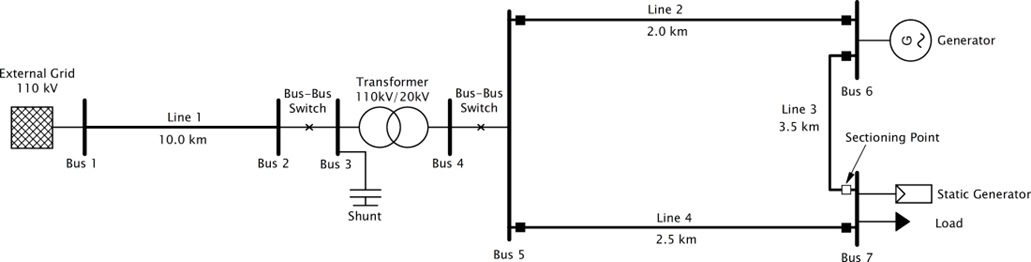

The trafo is equipped with a tap changer. The shunt is fixed. There are no timeseries included in the example. 

If we vary the infeed powers of the generators between 0..15 MVA / -12..12 MVar and consider both no-load and high-load (25 MVA) cases, we get some very extreme configuration with line loadings over 100%. E.g. line 2 is overloaded for multiple cases when Qsgen=-12 MVar, and line 1 is overloaded for multiple configurations when Pgen=12 MVA. Meanwhile, min/max voltage levels over all buses stay within 1 .. 1.05 p.U. for all cases. 

If the line lengths of line 2 and 4 are quadrupled, min/max voltages move between 0.935 .. 1.093 p.U. while line loadings look similar to before. When the line lengths stay original but line types are changed to the next weaker std type (NA2XS2Y 1x185 RM/25 12/20 kV), we still only get overloads if the absolute sgen reactive power exceeds 8. With the lines even weaker (NA2XS2Y 1x95 RM/25 12/20 kV), overloadings are possible with reactive power absolutes of 4 or less; notably, there are overloading cases with reactive powers of both generators being zero. Meanwhile voltages move between 0.996 .. 1.052 p.U. If line lengths are quadrupled in addition to that, line loadings would rise even more (up to 160%) and voltages would move between 0.91 .. 1.112 p.U.

To summarize, replacing the line types for lines 2 and 4 by NA2XS2Y 1x95 RM/25 12/20 kV while leaving line lengths unchanged would create an interesting use case for congestion management. A fixed cos phi could be set for both generators. To create a slightly more interesting scenario, it seems feasible to replace the gen by an sgen and treat the sgen at bus 6 as a wind farm, the one at bus 7 as PV plant. When cos phi for the generators is fixed to 0.98 and for the load to 0.95, line overloads may occur for certain load cases as soon as any of the generator's active powers exceeds 9 MVA. The trafo loading stays below 78% at all times. Voltages move between 0.99 .. 1.06 p.U.

The adapted network can be obtained by:

In [2]:
net = pp.networks.example_simple()
pp.change_std_type(net,1,'NA2XS2Y 1x95 RM/25 12/20 kV','line')
pp.change_std_type(net,3,'NA2XS2Y 1x95 RM/25 12/20 kV','line')    
net.gen = net.gen.drop(0) # drop gen at bus 7        
pp.create_sgen(net, 5, p_mw=10, q_mvar=0, sn_mva=12, name="WPP", index=1) # create new 'PV' sgen at bus 7 
net.sgen.at[0,'name'] = 'PV' # make other sgen 'WPP' 
net.sgen.at[0,'q_mvar'] = 0 
net.load.at[0,'scaling'] = 1

### Timeseries

Timeseries for WPP and PV sgens for this example were generated using renewable.ninja for locations near Hambach/Pfalz. There are already two wind power plants at the location and there is sufficient space for PV. Maximal peak powers of 12 MVA for both generators are chosen for generation of hourly timeseries. The cosphi is set to 1. For the load, the standard load profile G0-M is taken from the SimBench dataset. This contains quarter-hourly normalized active and reactive powers. Only the values at the full hours are taken and multiplied by 4 to obtain an hourly MW / MVar timeseries. 
A pp timeseries simulation was carried out with the resulting network. The resulting line loadings exceed 100% for multiple times in the year and both the lines that were weakened compared to the original network. The bus voltages stay between 0.992 .. 1,037 p.U. The max trafo loading is 60%.

The network including timeseries is stored as "simple_example.json" in the test folder under the pp_pict_connector git. In there you can also find a Python script which creates this network by adding the timeseries to the base net. 

### ICT network

In the next step, the pandapower network is extended by an ICT network. The basis for this is fixing controllable elements, measurements and interconnecting ICT nodes. Used protocols and information to be transmitted for the use case in mind should also be defined. In our example, the use case might be about active/reactive power control for voltage or line/trafo load regulation. The following image shows the network with pandaICT net on top. 

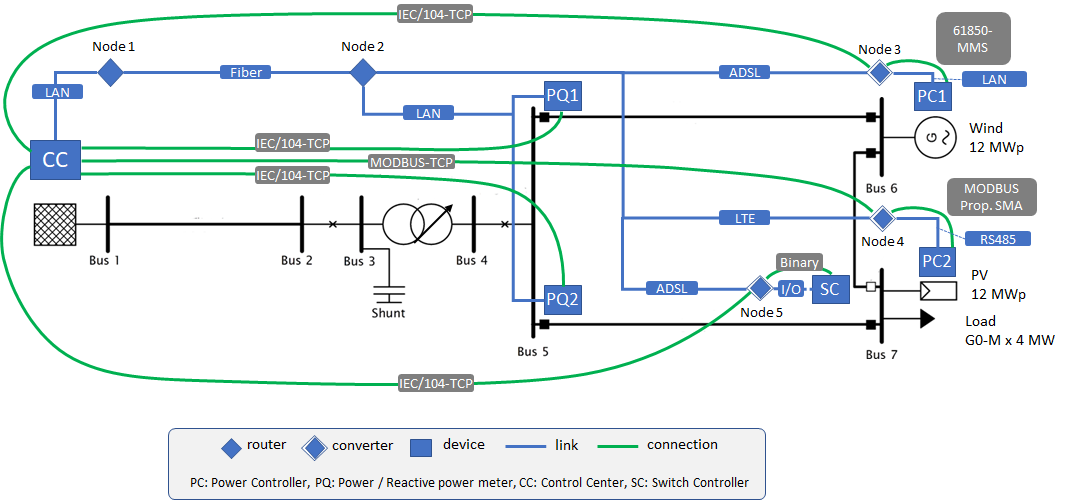


The pandaICT net can be fetched by the following code:

In [2]:
from   pandaict.networks import test_networks
ict_net = test_networks.create_testnet1()
print(ict_net)


This pandapower network includes the following parameter tables:
   - node (2 elements)
   - link (10 elements)
   - device (9 elements)
   - app (9 elements)
   - conn (8 elements)


The network includes a grid operator control center (left side, "CC") that is connected over different nodes, links and converters to Wind power plant and PV plant (right side). The generators are equipped with ICT devices that represent power controllers ("PC"). Nodes are placed at pp buses 1 and 3. Also, there are connections to two PQ meters (middle, at bus 5, "PQ") which are supposed to be situated in a HV/MV substation together with Node 2. There is a switch controller "SC" at bus 7. Note that there are three converter-type devices for protocol conversion: Node 3 is situated at bus 6 and has a LAN connection to the Wind power plant controller, Node 4 is situated at the PV plant main connection cabinet and is connected to its controller by a local network. Node 5 is situated at the bus 7 substation, connecting to the switch controller by a binary link.

On the logical level, connections are shown in green, and protocols are given as tags. Note that the Apps are not explicitly shown, but one app is present at each connection endpoint. The Control Center may generally host multiple apps, but currently it is modeled with a single one. On each converter-type device an app is running which is specified to convert between the named protocols. 

Information items can be defined according to the underlying use case, which may foresee the control center receiving measurements for power from the power controllers and PQ meters. This is currently implemented in the model that is obtained by the code above, using VALUE and ACK InfoItems which are available to the pandaict core. Target values to the power and switch controllers might be added. 

The setup could thus be used for the CC to perform active or reactive power curtailment as well as network topology change in case of network congestion as indicated by the PQ meters. There are timeseries for Wind and PV plants available for this use case.
This simple example may now be used to try out different pandaICT functionalities, including connection test and calculation of ICT link loading. It may also be embedded into a timeseries simulation with pandapower.